# M3.4 · 排序学习（Learning to Rank）与 NDCG

> 选股本质是"排序"：我们更关心头部股票排得准不准，而不是所有股票的涨跌幅误差。
> 排序学习直接优化排序，本节用 LightGBM LambdaRank，并用 NDCG 评估头部排序质量。

## 一、排序学习与 NDCG

**三类排序方法：**
- Pointwise：逐样本预测（普通回归）；
- Pairwise：学两两先后（如 RankNet）；
- Listwise：直接优化整组排序（如 LambdaRank）。

**NDCG@k：** 头部 k 个位置的排序质量，归一化到 [0,1]。
- DCG：按预测排序，相关性越高、位置越靠前得分越高，并用位置折扣；
- NDCG = DCG / 理想排序的 IDCG。

$$DCG@k=\sum_{i=1}^{k}\frac{2^{rel_i}-1}{\log_2(i+1)},\qquad NDCG=\frac{DCG}{IDCG}$$


## 二、构造数据与相关性等级

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import hfactors
from factor_lab2.combine import cross_zscore
from model_lab2 import labels, ranker
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume'],
                 start_time='2018-01-01', freq='day')
op=raw['$open'].unstack('instrument'); cl=raw['$close'].unstack('instrument')
hi=raw['$high'].unstack('instrument'); lo=raw['$low'].unstack('instrument')
vo=raw['$volume'].unstack('instrument')
lab = labels.cs_rank_label(cl, 5)
hf = hfactors.build_hf_factors(op, cl, hi, lo, vo)
feat_names = ['已实现波动20','日内动量20','尾盘位置20','量价相关20','收益偏度60']
z = pd.concat({n: cross_zscore(hf[n]).stack() for n in feat_names}, axis=1)
z.index.names = ['datetime','instrument']
rel = ranker.make_relevance(lab, 5).stack().rename('rel')
df = z.join(rel).dropna()
print('相关性等级分布:')
print(df['rel'].value_counts().sort_index().to_string())
cut = df.index.get_level_values('datetime').unique()
split = cut[int(len(cut)*0.8)]
rtr = df[df.index.get_level_values('datetime') <= split]
rte = df[df.index.get_level_values('datetime') > split]
print('训练/测试:', rtr.shape, rte.shape)

[1356:MainThread](2026-10-31 09:42:39,423) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[1356:MainThread](2026-10-31 09:42:41,284) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[1356:MainThread](2026-10-31 09:42:41,285) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


相关性等级分布:
rel
0.0    107955
1.0    107984
2.0    108134
3.0    107756
4.0    107755
训练/测试: (417073, 6) (122511, 6)


## 三、训练 LambdaRank 并评估 NDCG

In [2]:
model = ranker.train_lgbm_ranker(rtr, feat_names)
ndcg10 = ranker.evaluate_ndcg(model, rte, feat_names, k=10)
print('样本外 NDCG@10=%.4f (中位数 %.4f)' % (ndcg10.mean(), ndcg10.median()))
# 不同 k
for k in (5,10,20,30):
    s = ranker.evaluate_ndcg(model, rte, feat_names, k=k)
    print('NDCG@%d = %.4f' % (k, s.mean()))

样本外 NDCG@10=0.3992 (中位数 0.3830)


NDCG@5 = 0.3982


NDCG@10 = 0.3992


NDCG@20 = 0.4066


NDCG@30 = 0.4072


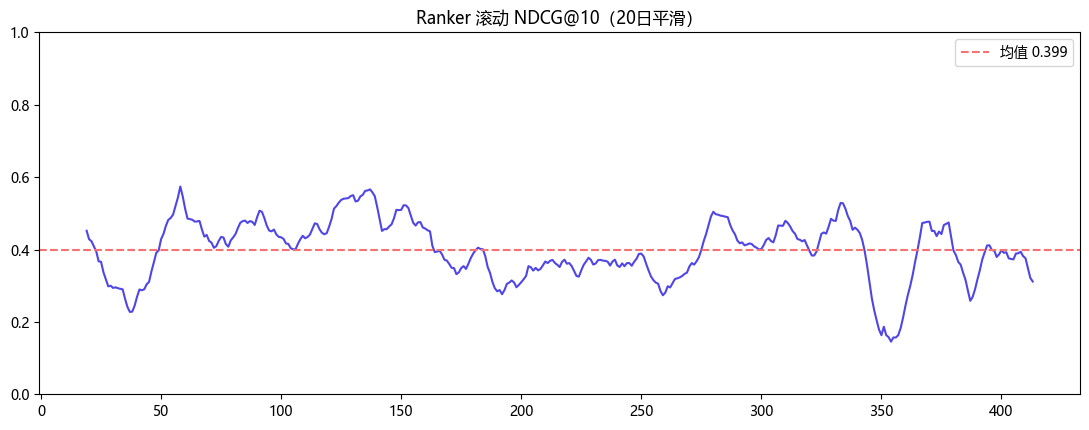

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(11,4.4))
ax.plot(ndcg10.index, ndcg10.rolling(20).mean(), color='#4f46e5')
ax.axhline(ndcg10.mean(), color='#f87171', ls='--',
           label='均值 %.3f'%ndcg10.mean())
ax.set_title('Ranker 滚动 NDCG@10（20日平滑）'); ax.set_ylim(0,1); ax.legend()
plt.tight_layout(); plt.show()

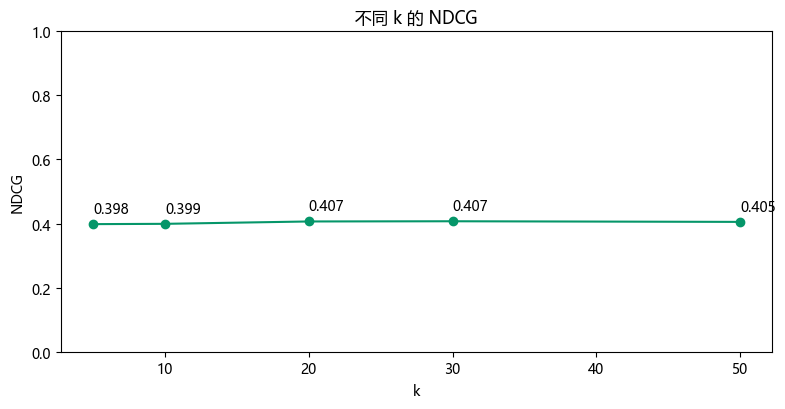

In [4]:
ks = [5,10,20,30,50]
vals = [ranker.evaluate_ndcg(model, rte, feat_names, k=k).mean() for k in ks]
fig, ax = plt.subplots(figsize=(8,4.2))
ax.plot(ks, vals, marker='o', color='#059669')
for k,v in zip(ks,vals):
    ax.annotate('%.3f'%v, (k,v), textcoords='offset points', xytext=(0,8))
ax.set_xlabel('k'); ax.set_ylabel('NDCG'); ax.set_title('不同 k 的 NDCG')
ax.set_ylim(0,1)
plt.tight_layout(); plt.show()

## 四、单组 NDCG 算例（理解公式）

In [5]:
true_rel = [3,2,3,0,1,2]
pred = [0.9,0.8,0.7,0.6,0.5,0.4]
print('NDCG@6 =', round(ranker.ndcg_at_k(true_rel, pred, 6),4))
# 打乱预测排序
pred_bad = [0.4,0.5,0.6,0.7,0.8,0.9]
print('差排序 NDCG@6 =', round(ranker.ndcg_at_k(true_rel, pred_bad, 6),4))
print('理想排序 NDCG =', round(ranker.ndcg_at_k(sorted(true_rel,reverse=True),
      sorted(true_rel,reverse=True),6),4))

NDCG@6 = 0.9488
差排序 NDCG@6 = 0.7057
理想排序 NDCG = 1.0


## 五、小结与面试要点

**面试高频：**
- 为什么选股用排序学习？（答：选股关注头部相对排序，NDCG/LambdaRank 直接优化排序而非全局误差）
- NDCG 公式与含义？（答：相关性增益按位置对数折扣，再除以理想排序，范围[0,1]）
- Pointwise/Pairwise/Listwise 区别？（答：逐样本/学两两/整组优化，LambdaRank 属 listwise）
- NDCG 与 IC 的关系？（答：IC衡量整体单调相关，NDCG聚焦头部排序，互补）
- 相关性等级怎么构造？（答：按截面把标签分桶成0~n-1档）

## 动手练习
1. 构造相关性等级并训练 LambdaRank；
2. 计算不同 k 的 NDCG 并画时序；
3. 用单组数据手算 NDCG 验证公式。

---
M3 模型进阶（上）完成，下一批 B5 进入模型进阶（下）。